# 손실 함수의 확률적 의미: MSE와 Cross-Entropy는 최대우도추정(MLE)이다

손실 함수는 아무렇게나 고른 식이 아니다. "정답이 어떤 확률 분포를 따른다"고 가정하고 그 분포의 우도(likelihood)를 가장 크게 만드는 파라미터를 찾으면, 그 음의 로그가 곧 손실 함수가 된다.

| 장 | 내용 |
|---|---|
| 1 | 확률 분포 시각화 (정규분포 PDF 2종, 베르누이 PMF 2종) |
| 2 | 소프트맥스 구현과 합 검증 |
| 3 | MSE 최소화 = 정규분포 가정 하의 MLE (유도 + 수치 확인) |
| 4 | Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정 하의 MLE (유도 + 수치 확인) |
| 5 | 두 손실의 확률적 의미 비교 |
| 6 | (보너스) 엔트로피, KL-Divergence, Cross-Entropy |

계산 함수는 `src/probability.py`에 있고, 그림은 `outputs/`에 PNG로 저장한다.

In [1]:
# 경로 설정과 모듈 불러오기
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

# 노트북 폴더의 한 단계 위(프로젝트 최상위)를 import 경로에 넣는다
sys.path.insert(0, str(Path.cwd().parent))

# 공통 상수(시드, 저장 경로)를 가져온다
from src.constants import FIGURE_DPI, RANDOM_SEED, output_path

# 확률/통계 모듈에서 필요한 함수를 가져온다
from src.probability import (
    bernoulli_pmf,
    binary_cross_entropy,
    categorical_cross_entropy,
    cross_entropy,
    entropy,
    gaussian_negative_log_likelihood,
    kl_divergence,
    mean_squared_error,
    normal_pdf,
    plot_bernoulli_pmfs,
    plot_normal_pdfs,
    softmax,
)

# 재현성을 위해 시드를 고정한다 (과제 요구)
np.random.seed(RANDOM_SEED)

## 1. 확률 분포 시각화

### 1.1 정규분포 PDF: $N(0, 1)$ vs $N(2, 0.5)$

$$
p(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)
$$

- 표기 $N(\mu, \sigma^2)$를 따라 두 번째 숫자를 **분산**으로 본다. $N(2, 0.5)$는 평균 2, 분산 0.5(표준편차 약 0.707)이다.
- PDF(확률 밀도 함수)는 연속 변수의 함수라 값 자체는 확률이 아니고, 곡선 아래 넓이가 확률이다. 그래서 분산이 작으면 꼭대기가 1/√(2π·0.5) ≈ 0.564까지 올라간다.

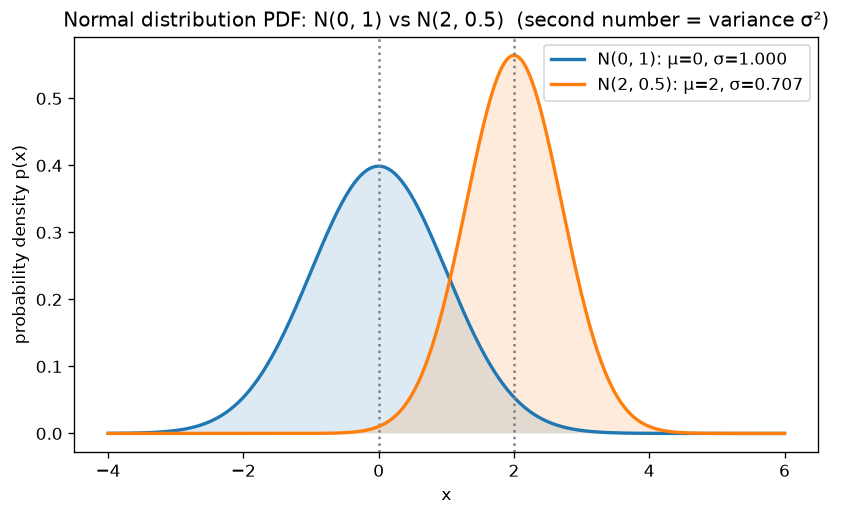

N(0, 1) 꼭대기 높이 = 0.3989
N(2, 0.5) 꼭대기 높이 = 0.5642


In [2]:
# 두 정규분포 PDF를 한 Figure에 그려 outputs/normal_pdf.png로 저장한다
plot_normal_pdfs("normal_pdf.png")

# 저장한 그림을 노트북에 보여 준다
display(Image(filename=str(output_path("normal_pdf.png"))))

# 꼭대기(평균 위치) 높이를 확인한다
for mean, variance in ((0.0, 1.0), (2.0, 0.5)):
    # 평균에서의 확률 밀도 = 1 / √(2πσ²)
    peak_density = float(normal_pdf(np.array([mean]), mean, variance)[0])

    # 결과를 출력한다
    print(f"N({mean:g}, {variance:g}) 꼭대기 높이 = {peak_density:.4f}")

### 1.2 베르누이 PMF: $B(0.3)$ vs $B(0.7)$

$$
P(X = k \mid p) = p^{k} (1 - p)^{1 - k}, \quad k \in \{0, 1\}
$$

- 결과가 0 또는 1뿐인 사건(동전, 합격/불합격, 클릭/미클릭)의 분포이다.
- PMF(확률 질량 함수)는 각 값의 확률 그 자체이다. $B(0.3)$은 $P(1) = 0.3,\ P(0) = 0.7$ 이고, $B(0.7)$은 그 반대이다.

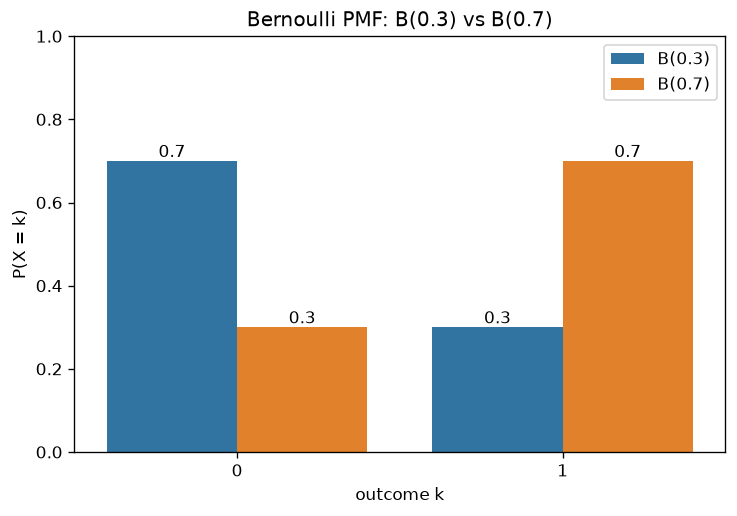

B(0.3): P(0)=0.7, P(1)=0.3, 합=1.0
B(0.7): P(0)=0.3, P(1)=0.7, 합=1.0


In [3]:
# 두 베르누이 PMF를 한 Figure에 막대그래프로 그려 저장한다
plot_bernoulli_pmfs("bernoulli_pmf.png")

# 저장한 그림을 노트북에 보여 준다
display(Image(filename=str(output_path("bernoulli_pmf.png"))))

# 분포마다 확률 합이 1인지 확인한다
for success_probability in (0.3, 0.7):
    # P(0), P(1)을 구한다
    probabilities = bernoulli_pmf(np.array([0, 1]), success_probability)

    # 결과를 출력한다
    print(
        f"B({success_probability}): P(0)={probabilities[0]:.1f}, "
        f"P(1)={probabilities[1]:.1f}, 합={probabilities.sum():.1f}"
    )

## 2. 소프트맥스 함수

$$
\operatorname{softmax}(z)_i = \frac{e^{z_i - \max z}}{\sum_j e^{z_j - \max z}}
$$

- 점수(로짓) 벡터를 "합이 1이고 모두 양수인" 확률 벡터로 바꾼다. 다중 분류 모델의 마지막 층에서 카테고리 분포의 파라미터를 만든다.
- 분자와 분모에서 같은 $e^{-\max z}$가 약분되므로 최댓값을 빼도 결과가 같다. 빼지 않으면 $e^{1000}$ 같은 값이 overflow(무한대)가 된다.

In [4]:
# 시드로 만든 무작위 로짓과 극단적인 로짓을 함께 시험한다
test_logits = {
    # 과제 예시 같은 평범한 로짓
    "[2.0, 1.0, 0.1]": np.array([2.0, 1.0, 0.1]),
    # 시드 42로 만든 무작위 로짓 10개
    "random 10 (seed 42)": np.random.randn(10),
    # 최댓값을 빼지 않으면 overflow가 나는 큰 로짓
    "[1000, 1001, 1002]": np.array([1000.0, 1001.0, 1002.0]),
}

# 로짓마다 소프트맥스를 적용하고 합을 확인한다
for logits_name, logits in test_logits.items():
    # 확률 벡터로 바꾼다
    probabilities = softmax(logits)

    # 합과 1.0의 차이
    sum_difference = abs(float(probabilities.sum()) - 1.0)

    # 1e-6 이내인지 판정한다
    verdict = "통과" if sum_difference < 1e-6 else "실패"

    # 결과를 출력한다
    print(
        f"{logits_name:<20} -> 합={probabilities.sum():.10f}, "
        f"|합-1|={sum_difference:.1e} (1e-6 이내 {verdict})"
    )

# 평범한 로짓의 확률 벡터를 구한다
example_probabilities = softmax(test_logits["[2.0, 1.0, 0.1]"])

# 4자리로 반올림해 출력한다
print("\nsoftmax([2.0, 1.0, 0.1]) =", np.round(example_probabilities, 4).tolist())

[2.0, 1.0, 0.1]      -> 합=1.0000000000, |합-1|=0.0e+00 (1e-6 이내 통과)
random 10 (seed 42)  -> 합=1.0000000000, |합-1|=0.0e+00 (1e-6 이내 통과)
[1000, 1001, 1002]   -> 합=1.0000000000, |합-1|=1.1e-16 (1e-6 이내 통과)

softmax([2.0, 1.0, 0.1]) = [0.659, 0.2424, 0.0986]


## 3. MSE 최소화 = 정규분포 가정 하의 MLE

### 3.1 유도

**가정**: 정답은 모델 예측에 정규분포 잡음이 더해진 값이다.

$$
y_i = f(x_i) + \varepsilon_i, \quad \varepsilon_i \sim N(0, \sigma^2)
\quad\Longrightarrow\quad
p(y_i \mid x_i) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(y_i - f(x_i))^2}{2\sigma^2}\right)
$$

**1단계 — 우도**: 데이터 $n$개가 서로 독립이면 전체 확률은 곱이다.

$$
\mathcal{L}(f) = \prod_{i=1}^{n} p(y_i \mid x_i)
$$

**2단계 — 로그**: 곱은 다루기 어렵고 작은 수를 계속 곱하면 0에 가까워진다. $\log$는 증가 함수라 최댓값의 위치를 바꾸지 않으므로 합으로 바꾼다.

$$
\log \mathcal{L}(f) = \sum_{i=1}^{n} \left[ -\frac{(y_i - f(x_i))^2}{2\sigma^2} - \log\sqrt{2\pi\sigma^2} \right]
$$

**3단계 — 상수 제거**: $\sigma$가 고정이면 $-\log\sqrt{2\pi\sigma^2}$ 는 $f$와 상관없는 상수이고, $\frac{1}{2\sigma^2} > 0$ 은 최대 위치를 바꾸지 않는 양수 배율이다.

$$
\arg\max_f \log \mathcal{L}(f) = \arg\max_f \left[ -\sum_{i=1}^{n} (y_i - f(x_i))^2 \right] = \arg\min_f \sum_{i=1}^{n} (y_i - f(x_i))^2
$$

**4단계 — 평균**: $n$으로 나눠도 최소 위치는 같다.

$$
\arg\min_f \frac{1}{n}\sum_{i=1}^{n} (y_i - f(x_i))^2 = \arg\min_f \operatorname{MSE}
$$

**결론**: 잡음이 정규분포라고 가정하면, 우도를 최대로 만드는 모델과 MSE를 최소로 만드는 모델은 같다. 제곱 오차인 이유는 정규분포 지수 안의 $(y - \mu)^2$ 때문이다.

### 3.2 수치로 확인

시드 42로 $y = 3 + \varepsilon,\ \varepsilon \sim N(0, 1)$ 인 데이터 50개를 만들고, 상수 예측 $\hat{y} = c$ 의 후보마다 MSE와 정규분포 음의 로그우도(NLL)를 계산한다. 두 곡선의 최소점이 같은 $c$ (표본 평균)에 있어야 한다.

MSE 최소 c = 2.77, 정규분포 NLL 최소 c = 2.77, 표본 평균 = 2.7745
NLL - (MSE/2 + ½log 2π) 최대 차이 = 1.8e-15


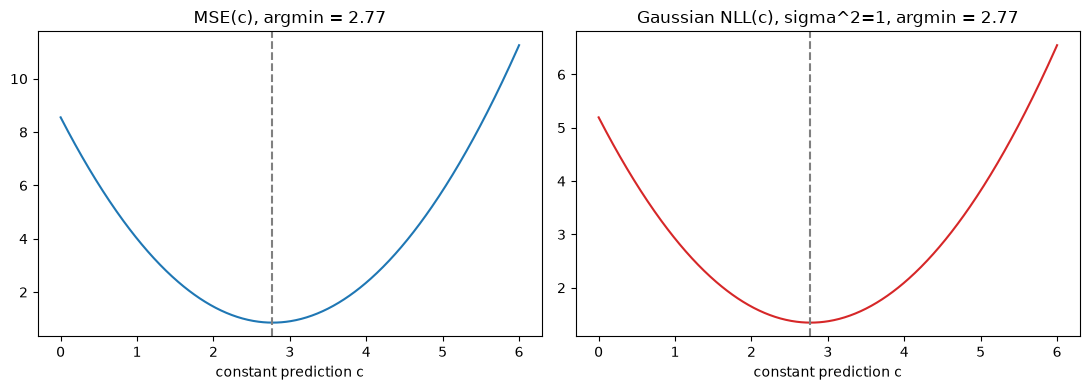

In [5]:
# 시드를 다시 고정해 같은 데이터를 만든다
np.random.seed(RANDOM_SEED)

# 참값 3에 표준정규 잡음을 더한 관측값 50개
observed_values = 3.0 + np.random.randn(50)

# 상수 예측 후보 c (0 ~ 6을 0.01 간격으로)
candidate_predictions = np.linspace(0.0, 6.0, 601)

# 후보마다 MSE를 구한다
mse_values = np.array(
    [
        mean_squared_error(observed_values, np.full(observed_values.size, candidate))
        for candidate in candidate_predictions
    ]
)

# 후보마다 정규분포(σ²=1) 평균 NLL을 구한다
nll_values = np.array(
    [
        gaussian_negative_log_likelihood(
            observed_values, np.full(observed_values.size, candidate), 1.0
        )
        for candidate in candidate_predictions
    ]
)

# MSE 최소 후보
best_by_mse = candidate_predictions[np.argmin(mse_values)]

# NLL 최소 후보
best_by_nll = candidate_predictions[np.argmin(nll_values)]

# 결과를 출력한다
print(
    f"MSE 최소 c = {best_by_mse:.2f}, 정규분포 NLL 최소 c = {best_by_nll:.2f}, "
    f"표본 평균 = {observed_values.mean():.4f}"
)

# NLL = MSE / 2σ² + ½log(2πσ²) 관계를 확인한다 (σ² = 1)
relation_gap = np.max(np.abs(nll_values - (mse_values / 2 + 0.5 * np.log(2 * np.pi))))

# 관계식 차이를 출력한다
print(f"NLL - (MSE/2 + ½log 2π) 최대 차이 = {relation_gap:.1e}")

# 두 곡선을 나란히 그린다
figure, (mse_axis, nll_axis) = plt.subplots(1, 2, figsize=(11, 4))

# 왼쪽에 MSE 곡선
mse_axis.plot(candidate_predictions, mse_values, color="tab:blue")

# MSE 최소 위치 표시
mse_axis.axvline(best_by_mse, linestyle="--", color="gray")

# 왼쪽 제목
mse_axis.set_title(f"MSE(c), argmin = {best_by_mse:.2f}")

# 왼쪽 x 이름
mse_axis.set_xlabel("constant prediction c")

# 오른쪽에 NLL 곡선
nll_axis.plot(candidate_predictions, nll_values, color="tab:red")

# NLL 최소 위치 표시
nll_axis.axvline(best_by_nll, linestyle="--", color="gray")

# 오른쪽 제목
nll_axis.set_title(f"Gaussian NLL(c), sigma^2=1, argmin = {best_by_nll:.2f}")

# 오른쪽 x 이름
nll_axis.set_xlabel("constant prediction c")

# 여백 정리
figure.tight_layout()

# outputs/에 저장한다
figure.savefig(
    output_path("mse_vs_gaussian_nll.png"), dpi=FIGURE_DPI, bbox_inches="tight"
)

# 노트북에 그림을 보여 준다
plt.show()

## 4. Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정 하의 MLE

### 4.1 이진 분류: 베르누이 분포

**가정**: 정답 $y_i \in \{0, 1\}$ 은 모델이 낸 확률 $\hat{y}_i = \sigma(z_i)$ 를 성공 확률로 하는 베르누이 분포를 따른다.

$$
p(y_i \mid x_i) = \hat{y}_i^{\,y_i} (1 - \hat{y}_i)^{1 - y_i}
$$

**1단계 — 우도와 로그**

$$
\log \mathcal{L} = \sum_{i=1}^{n} \log\!\left[\hat{y}_i^{\,y_i} (1 - \hat{y}_i)^{1 - y_i}\right] = \sum_{i=1}^{n} \left[ y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right]
$$

**2단계 — 부호를 바꿔 최소화 문제로**

$$
\arg\max \log \mathcal{L} = \arg\min \left( -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log \hat{y}_i + (1 - y_i) \log (1 - \hat{y}_i) \right] \right) = \arg\min \operatorname{BCE}
$$

- $y_i = 1$ 이면 $-\log \hat{y}_i$ 만 남고, $y_i = 0$ 이면 $-\log(1 - \hat{y}_i)$ 만 남는다. 정답에 준 확률이 낮을수록 손실이 커진다.
- 역전파 노트북의 손실 $L = -(y \log \hat{y} + (1 - y)\log(1 - \hat{y}))$ 이 바로 이 식이다.

### 4.2 다중 분류: 카테고리 분포

**가정**: 정답 클래스는 소프트맥스 출력 $\hat{\mathbf{y}}_i = \operatorname{softmax}(z_i)$ 를 파라미터로 하는 카테고리 분포를 따른다. 정답을 원-핫 벡터 $\mathbf{y}_i$ 로 쓰면

$$
p(\mathbf{y}_i \mid x_i) = \prod_{k=1}^{K} \hat{y}_{i,k}^{\,y_{i,k}}
\quad\Longrightarrow\quad
-\log \mathcal{L} = -\sum_{i=1}^{n} \sum_{k=1}^{K} y_{i,k} \log \hat{y}_{i,k} = \sum_{i=1}^{n} \operatorname{CE}(\mathbf{y}_i, \hat{\mathbf{y}}_i)
$$

- 원-핫이라 정답 클래스 $c$ 항만 남아 $\operatorname{CE} = -\log \hat{y}_{i,c}$ 이다.
- $K = 2$ 이면 4.1의 BCE와 같은 식이 된다.

**결론**: 분류 정답이 베르누이/카테고리 분포를 따른다고 가정하면, 우도를 최대로 만드는 모델과 Cross-Entropy를 최소로 만드는 모델은 같다.

### 4.3 수치로 확인

In [6]:
# 시드를 고정해 같은 데이터를 만든다
np.random.seed(RANDOM_SEED)

# 실제 성공 확률 0.3인 베르누이 정답 200개
binary_targets = (np.random.rand(200) < 0.3).astype(np.float64)

# 모든 데이터에 같은 확률 q를 예측하는 후보 (0.01 ~ 0.99)
candidate_probabilities = np.linspace(0.01, 0.99, 99)

# 후보마다 BCE를 구한다
bce_values = np.array(
    [
        binary_cross_entropy(binary_targets, np.full(binary_targets.size, candidate))
        for candidate in candidate_probabilities
    ]
)

# 후보마다 베르누이 PMF로 직접 구한 평균 음의 로그우도
bernoulli_nll_values = np.array(
    [
        -np.mean(np.log(bernoulli_pmf(binary_targets, candidate)))
        for candidate in candidate_probabilities
    ]
)

# BCE와 베르누이 NLL이 같은 값인지 확인한다
bce_gap = np.max(np.abs(bce_values - bernoulli_nll_values))

# 최대 차이를 출력한다
print(f"BCE와 베르누이 NLL 최대 차이 = {bce_gap:.1e}")

# BCE 최소 후보와 표본의 1 비율(MLE 해)을 비교한다
print(
    f"BCE 최소 q = {candidate_probabilities[np.argmin(bce_values)]:.2f}, "
    f"표본에서 1의 비율 = {binary_targets.mean():.3f}"
)

# 카테고리 분포: 로짓을 소프트맥스로 확률로 바꾼다
class_probabilities = softmax(np.array([2.0, 1.0, 0.1]))

# 정답이 첫 번째 클래스인 원-핫 벡터
one_hot_target = np.array([1.0, 0.0, 0.0])

# 원-핫 CE와 -log(정답 확률)을 비교한다
print(
    f"CE = {categorical_cross_entropy(one_hot_target, class_probabilities):.4f}, "
    f"-log(정답 클래스 확률) = {-np.log(class_probabilities[0]):.4f}"
)

# K=2일 때 CE와 BCE가 같은지 확인한다 (정답 1, 예측 확률 0.8)
two_class_ce = categorical_cross_entropy(np.array([0.0, 1.0]), np.array([0.2, 0.8]))

# 같은 상황의 BCE
two_class_bce = binary_cross_entropy(np.array([1.0]), np.array([0.8]))

# 두 값을 비교해 출력한다
print(
    f"K=2: CE([0,1], [0.2,0.8]) = {two_class_ce:.4f}, BCE(1, 0.8) = {two_class_bce:.4f}"
)

BCE와 베르누이 NLL 최대 차이 = 0.0e+00
BCE 최소 q = 0.33, 표본에서 1의 비율 = 0.330
CE = 0.4170, -log(정답 클래스 확률) = 0.4170
K=2: CE([0,1], [0.2,0.8]) = 0.2231, BCE(1, 0.8) = 0.2231


## 5. 두 손실의 확률적 의미 비교

| 구분 | MSE | Cross-Entropy |
|---|---|---|
| 가정하는 정답 분포 | 정규분포 $N(f(x), \sigma^2)$ | 베르누이 $B(\hat{y})$ / 카테고리 $\operatorname{Cat}(\hat{\mathbf{y}})$ |
| 모델 출력의 의미 | 분포의 평균 $\mu$ | 클래스별 확률 |
| 정답의 종류 | 연속값 (회귀) | 0/1, 클래스 (분류) |
| 손실이 커지는 경우 | 예측과 정답의 거리가 멀 때 (제곱) | 정답에 준 확률이 작을 때 ($-\log$) |
| MLE와의 관계 | 정규분포 NLL $= \dfrac{\text{MSE}}{2\sigma^2} + $ 상수 | 베르누이/카테고리 NLL $=$ CE |

- 분류 문제에 MSE를 쓰면 "정답이 정규분포를 따른다"는 맞지 않는 가정을 하는 셈이다. 또 Sigmoid 출력이 0이나 1에 가까우면 기울기 $\hat{y}(1 - \hat{y})$ 가 작아져 학습이 느려진다. Cross-Entropy는 역전파 노트북의 $\partial L/\partial z_2 = \hat{y} - y$ 처럼 이 항이 지워진다.

## 6. (보너스) 정보 이론: 엔트로피, KL-Divergence, Cross-Entropy

$$
H(p) = -\sum_i p_i \log p_i, \qquad
D_{KL}(p \,\|\, q) = \sum_i p_i \log \frac{p_i}{q_i}, \qquad
H(p, q) = -\sum_i p_i \log q_i = H(p) + D_{KL}(p \,\|\, q)
$$

- 엔트로피 $H(p)$: 분포의 불확실성. 결과가 고를수록 크다.
- KL-Divergence: 실제 분포 $p$ 대신 모델 분포 $q$를 쓸 때 늘어나는 정보량. 항상 0 이상이고 $p = q$ 일 때만 0이다. 대칭이 아니다.
- 학습에서 $p$(데이터)는 고정이라 $H(p)$는 상수이다. 그래서 **Cross-Entropy를 줄이는 것 = KL을 줄이는 것 = 모델 분포를 데이터 분포에 가깝게 만드는 것**이다.

In [7]:
# 실제 분포 p와 모델 분포 q
true_distribution = np.array([0.1, 0.6, 0.3])

# 모델 분포 q
model_distribution = np.array([0.3, 0.4, 0.3])

# 엔트로피 H(p)
true_entropy = entropy(true_distribution)

# KL(p || q)
forward_kl = kl_divergence(true_distribution, model_distribution)

# KL(q || p) (비대칭 확인용)
reverse_kl = kl_divergence(model_distribution, true_distribution)

# Cross-Entropy H(p, q)
true_model_cross_entropy = cross_entropy(true_distribution, model_distribution)

# 결과를 출력한다
print(
    f"H(p) = {true_entropy:.4f}, KL(p||q) = {forward_kl:.4f}, "
    f"H(p,q) = {true_model_cross_entropy:.4f}"
)

# 분해 관계를 확인한다
decomposition_gap = abs(true_entropy + forward_kl - true_model_cross_entropy)

# 분해 결과를 출력한다
print(
    f"H(p) + KL(p||q) = {true_entropy + forward_kl:.4f} "
    f"-> H(p,q)와 차이 {decomposition_gap:.1e}"
)

# KL의 비대칭을 확인한다
print(f"KL(p||q) = {forward_kl:.4f}, KL(q||p) = {reverse_kl:.4f} -> 대칭이 아니다")

# 고른 분포가 엔트로피 최대임을 확인한다
print(
    f"공정한 동전 H = {entropy(np.array([0.5, 0.5])):.4f} (= log 2 = {np.log(2):.4f}), "
    f"치우친 동전 B(0.9) H = {entropy(np.array([0.9, 0.1])):.4f}"
)

H(p) = 0.8979, KL(p||q) = 0.1334, H(p,q) = 1.0314
H(p) + KL(p||q) = 1.0314 -> H(p,q)와 차이 0.0e+00
KL(p||q) = 0.1334, KL(q||p) = 0.1674 -> 대칭이 아니다
공정한 동전 H = 0.6931 (= log 2 = 0.6931), 치우친 동전 B(0.9) H = 0.3251


## 정리

- 정규분포 $N(0,1)$, $N(2,0.5)$ PDF와 베르누이 $B(0.3)$, $B(0.7)$ PMF를 각각 하나의 Figure에 비교했다. (`outputs/normal_pdf.png`, `outputs/bernoulli_pmf.png`)
- 소프트맥스 출력의 합은 세 경우 모두 1과의 차이가 1e-6 이내였다. 최댓값을 빼서 $[1000, 1001, 1002]$ 도 overflow 없이 계산했다.
- MSE와 정규분포 NLL, BCE와 베르누이 NLL은 같은 위치에서 최소가 된다. 손실 함수를 고르는 것은 정답의 확률 분포를 가정하는 것과 같다.